In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (r2_score,mean_absolute_error,mean_squared_error,mean_absolute_percentage_error,explained_variance_score,mean_absolute_percentage_error,
 explained_variance_score,max_error)

In [20]:
df=pd.read_csv("House_price.csv")

In [21]:
df.head(10)

,Area_sqft,Bedrooms,Bathrooms,House_Age_Years,Parking_Spaces,Distance_to_City_km,Price
0,2649,5,4.0,18,1,18.6,920406
1,4017,1,4.0,3,0,5.2,1077484
2,3463,1,3.0,30,1,9.1,773484
3,800,5,3.5,26,3,11.2,501097
4,2581,3,2.5,10,1,7.4,763041
5,2800,3,2.5,1,0,11.3,908701
6,1003,2,2.5,23,2,24.2,270665
7,1363,5,2.0,14,0,19.7,563236
8,2963,1,1.5,14,2,15.8,601819
9,1146,5,1.0,24,3,22.5,406832


In [22]:
df.tail(10)

,Area_sqft,Bedrooms,Bathrooms,House_Age_Years,Parking_Spaces,Distance_to_City_km,Price
490,1676,5,3.5,12,3,7.7,809439
491,754,4,2.5,11,2,22.7,399229
492,2285,1,2.5,4,2,1.5,746410
493,4225,5,1.5,28,3,23.3,920815
494,2641,5,2.0,28,3,6.6,743951
495,2917,1,3.0,5,3,4.1,872167
496,1891,1,1.5,25,0,13.2,370694
497,2569,2,2.0,11,0,11.3,636800
498,2674,3,3.0,21,2,5.5,802469
499,761,2,1.5,6,2,16.5,334362


In [23]:
df.size

3500

In [24]:
rows,columns =df.shape
print(f' No.of.Rows:{rows}')
print(f' No.of.Columns:{columns}')

 No.of.Rows:500
 No.of.Columns:7


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Area_sqft            500 non-null    int64  
 1   Bedrooms             500 non-null    int64  
 2   Bathrooms            500 non-null    float64
 3   House_Age_Years      500 non-null    int64  
 4   Parking_Spaces       500 non-null    int64  
 5   Distance_to_City_km  500 non-null    float64
 6   Price                500 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 27.5 KB


In [26]:
df.describe()

,Area_sqft,Bedrooms,Bathrooms,House_Age_Years,Parking_Spaces,Distance_to_City_km,Price
count,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,5.000000e+02
mean,2598.134000,3.022000,2.557000,14.976000,1.44800,12.838600,7.470893e+05
std,1102.979986,1.460748,0.869922,8.969075,1.12687,6.974529,2.388841e+05
min,601.000000,1.000000,1.000000,0.000000,0.00000,1.000000,2.236370e+05
25%,1674.250000,2.000000,2.000000,7.000000,0.00000,6.475000,5.621275e+05
50%,2575.000000,3.000000,2.500000,14.000000,1.00000,12.900000,7.456445e+05
75%,3575.250000,4.000000,3.500000,23.000000,2.00000,19.000000,9.271915e+05
max,4500.000000,5.000000,4.000000,30.000000,3.00000,24.900000,1.335513e+06


In [27]:
df.isnull().sum()

Area_sqft              0
Bedrooms               0
Bathrooms              0
House_Age_Years        0
Parking_Spaces         0
Distance_to_City_km    0
Price                  0
dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df=df.drop(['Parking_Spaces','Distance_to_City_km'],axis=1)

In [30]:
X=df.drop('Price',axis=1)
y=df.Price

In [31]:
model=LinearRegression()

In [32]:
x1,x2,y1,y2=train_test_split(X,y,test_size=0.8,random_state=42)

In [33]:
model.fit(x1,y1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 179.09,43228.28,69049.74,-7443.45]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Area_sqft','Bedrooms','Bathrooms','House_Age_Years']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.976e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [34]:
y_pred=model.predict(x2)

In [35]:
print(model.coef_)
print(model.intercept_)

[  179.08732629 43228.27878714 69049.74206064 -7443.45182112]
89764.51500012027


In [36]:
mae=mean_absolute_error(y2,y_pred)
mse=mean_squared_error(y2,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y2,y_pred)
mape = mean_absolute_percentage_error(y2, y_pred)
evs = explained_variance_score(y2, y_pred)
maxerr = max_error(y2, y_pred)
n=x2.shape[0]
p=x2.shape[1]
adj_r2=1-((1-r2)*(n-1)/(n-p-1))
print(f' Mean Absolute Error:{mae:.2f}')
print(f' Mean Squared Error:{mse:.2f}')
print(f' Root Mean Squared Error:{rmse:.2f}')
print(f' R2 Score:{r2:.4f}')
print(f' Adjusted R2 Score:{adj_r2:.4f}')
print(f'Mean Absolute Percentage Error (MAPE): {mape:.4f}')
print(f'Explained Variance Score: {evs:.4f}')
print(f'Maximum Error: {maxerr:.2f}')

 Mean Absolute Error:51525.63
 Mean Squared Error:4126403435.14
 Root Mean Squared Error:64237.09
 R2 Score:0.9246
 Adjusted R2 Score:0.9238
Mean Absolute Percentage Error (MAPE): 0.0800
Explained Variance Score: 0.9250
Maximum Error: 194584.30


In [37]:
print("\nIntercept:")
print(model.intercept_)


Intercept:
89764.51500012027


In [39]:
print(X.columns.tolist())
print("Number of features:", model.n_features_in_)

['Area_sqft', 'Bedrooms', 'Bathrooms', 'House_Age_Years']
Number of features: 4


In [40]:
print("\nCoefficients:")
coef = pd.DataFrame({
 "Feature": X.columns,
 "Coefficient": model.coef_
})
print(coef)
new_house = [[5000,3,2,2]]
prediction = model.predict(new_house)
print("\nPredicted House Price:", prediction[0])



Coefficients:
           Feature   Coefficient
0        Area_sqft    179.087326
1         Bedrooms  43228.278787
2        Bathrooms  69049.742061
3  House_Age_Years  -7443.451821

Predicted House Price: 1238098.563290241


C:\Users\acer\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


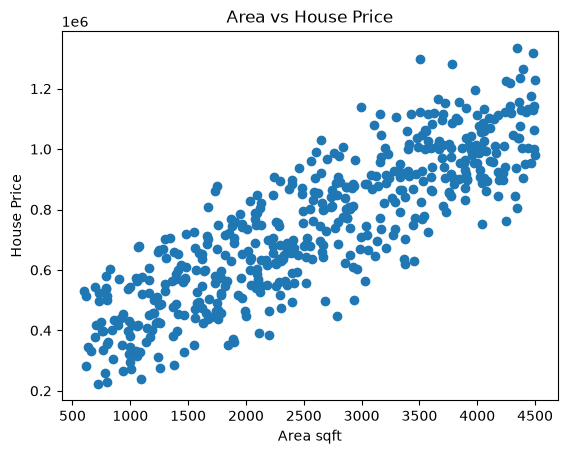

In [20]:
plt.scatter(df["Area_sqft"],df["Price"])
plt.xlabel("Area sqft")
plt.ylabel("House Price")
plt.title("Area vs House Price")
plt.show()